# Comportamiento de los modelos con fotos propias

Los modelos finales (`configuracion_fondos.json`: YOLOv11n y YOLOv11s con fondos negativos, 3 semillas cada uno) se aplican a 3 fotos propias tomadas con smartphone, fuera del dataset: otra cámara, otra iluminación y otros granos. El objetivo es ver si el comportamiento observado en el dataset se mantiene en condiciones distintas y, donde falle, identificar la causa.

**Fotos** (`fotos/propias/`):
- `imgPrueba` e `imgPrueba2`: los mismos 11 granos en dos disposiciones, con los sanos a la izquierda y los defectuosos a la derecha.
- `imgTest3`: 16 granos, sanos y defectuosos mezclados.

**Referencia** (`fotos/propias/referencia/`, formato YOLO):
- **Cajas:** el consenso de las detecciones de las 6 corridas: la mediana de las cajas que coinciden en al menos 4 corridas.
- **Clase:** asignada por inspección visual. `Defect` si el grano tiene moho, está partido o tiene manchas; `Healthy` en otro caso.

**Criterios:** como en el diagnóstico del test, con el umbral de conteo de cada modelo y NMS agnóstico a la clase. Un grano está acertado si una predicción lo cubre con IoU ≥ 0.5 y con la clase correcta.

Este análisis no entrena ni cambia los modelos.

In [1]:
import json
import os
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from PIL import Image

os.environ['YOLO_VERBOSE'] = 'False'   # sin barras de progreso de Ultralytics
from ultralytics import YOLO

import comun_oe2 as E

C = E.C
C.estilo()
RAIZ = Path.cwd()
FOTOS = E.FOTOS / 'propias'
SALIDA = RAIZ / 'salida' / '2.2d_fotos_propias'
CFG = E.configuracion('fondos')
ETIQUETA = {'yolo11n': 'YOLOv11n', 'yolo11s': 'YOLOv11s'}
CLASE = {0: 'Healthy', 1: 'Defect'}
MODELOS = {m: [(int(Path(p).parent.parent.name.split('_s')[-1].split('_')[0]), YOLO(str(p))) for p in c['pesos']]
           for m, c in CFG.items()}

def cargar_foto(stem):
    """Imagen BGR, cajas de referencia (x1, y1, x2, y2) y clases."""
    img = cv2.imread(str(FOTOS / f'{stem}.jpeg'))
    H, W = img.shape[:2]
    c, cl = C.leer_yolo(FOTOS / 'referencia' / f'{stem}.txt')
    c = np.array(c, float).reshape(-1, 4)
    return img, np.stack([(c[:, 0] - c[:, 2] / 2) * W, (c[:, 1] - c[:, 3] / 2) * H,
                          (c[:, 0] + c[:, 2] / 2) * W, (c[:, 1] + c[:, 3] / 2) * H], 1), np.array(cl)

def evaluar(img, cajas, clases, modelo, imgsz=E.IMGSZ):
    """Por semilla: detecciones, sanos y defectuosos acertados, y predicciones."""
    filas = []
    for semilla, mod in MODELOS[modelo]:
        r = mod.predict(img, imgsz=imgsz, conf=CFG[modelo]['conf_conteo'], agnostic_nms=True, verbose=False)[0]
        pb, pc = r.boxes.xyxy.cpu().numpy(), r.boxes.cls.cpu().numpy().astype(int)
        pares, _ = E.emparejar(cajas, pb)
        ok = np.array([g in pares and pc[pares[g]] == clases[g] for g in range(len(clases))])
        filas.append({'modelo': ETIQUETA[modelo], 'semilla': semilla, 'detecciones': len(pb),
                      'Healthy predichos': int((pc == 0).sum()), 'Defect predichos': int((pc == 1).sum()),
                      'sanos acertados': ok[clases == 0].mean() if (clases == 0).any() else np.nan,
                      'defectuosos acertados': ok[clases == 1].mean() if (clases == 1).any() else np.nan,
                      'cajas': pb, 'clases': pc})
    return filas

FOTOS_STEMS = ['imgPrueba', 'imgPrueba2', 'imgTest3']
REF = {s: cargar_foto(s) for s in FOTOS_STEMS}
display(pd.DataFrame({s: {'tamaño': f'{img.shape[1]} × {img.shape[0]}', 'granos': len(cl),
                          'Healthy': int((cl == 0).sum()), 'Defect': int((cl == 1).sum())}
                      for s, (img, _, cl) in REF.items()}).T)

,tamaño,granos,Healthy,Defect
imgPrueba,1496 × 1200,11,6,5
imgPrueba2,1463 × 1200,11,6,5
imgTest3,1280 × 960,16,8,8


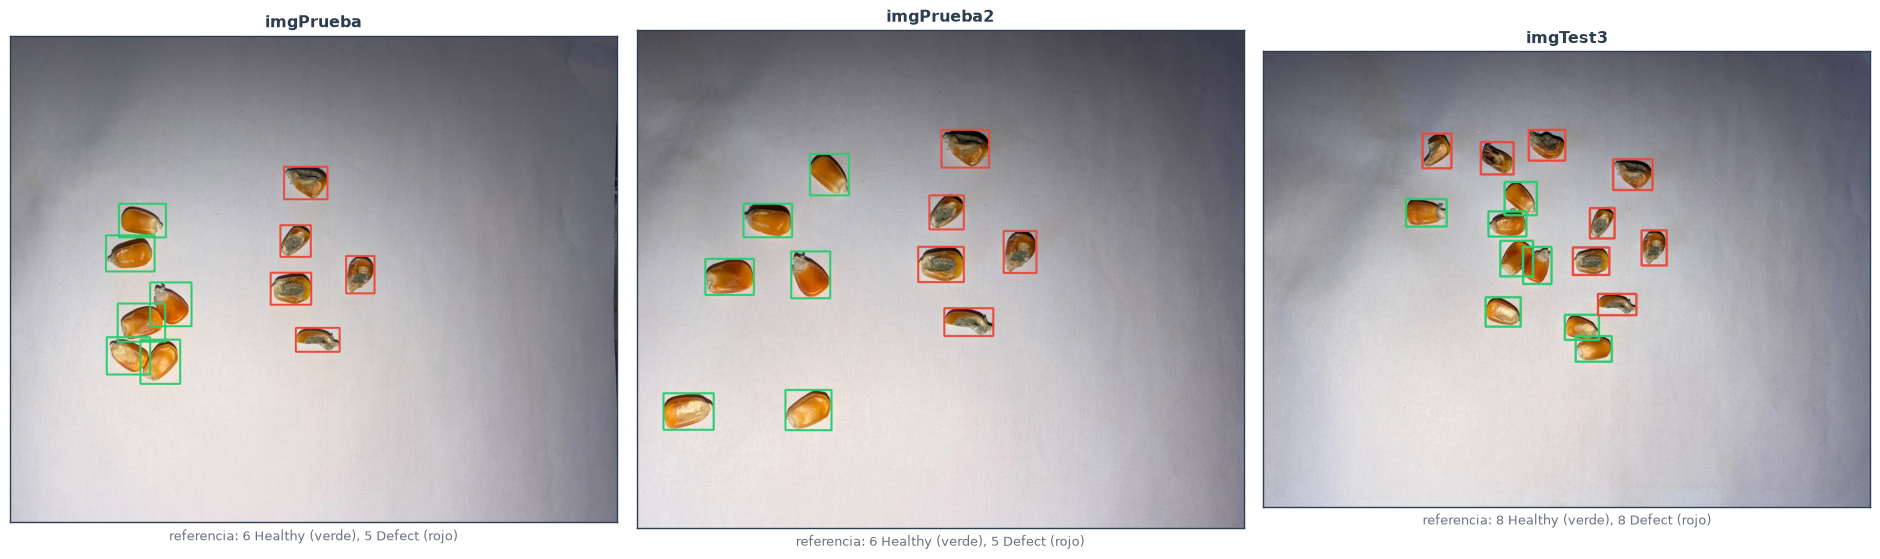

In [2]:
fig, axes = plt.subplots(1, 3, figsize=(19, 5.6))
for ax, (s, (img, cajas, cl)) in zip(axes, REF.items()):
    vista = E.dibujar(E.dibujar(cv2.cvtColor(img, cv2.COLOR_BGR2RGB), cajas[cl == 0], E.CAJA_OK, 4), cajas[cl == 1], E.CAJA_MAL, 4)
    E.mostrar(ax, vista, s, f'referencia: {(cl == 0).sum()} Healthy (verde), {(cl == 1).sum()} Defect (rojo)')
C.guardar(SALIDA, 'referencia.png')

## 1. Diferencias con `Data_final`

Características de las fotos frente a las imágenes de entrenamiento:
- **Calidad JPEG:** se estima a partir de la tabla de cuantización.
- **Lado del grano:** tamaño aparente a 1280 px, la escala a la que trabaja la red.
- **Color:** tono (H), saturación (S) y brillo (V) medios de los granos, y brillo del papel.

In [3]:
TABLA_IJG = np.array([16, 11, 10, 16, 24, 40, 51, 61, 12, 12, 14, 19, 26, 58, 60, 55, 14, 13, 16, 24, 40, 57, 69, 56,
                      14, 17, 22, 29, 51, 87, 80, 62, 18, 22, 37, 56, 68, 109, 103, 77, 24, 35, 55, 64, 81, 104, 113, 92,
                      49, 64, 78, 87, 103, 121, 120, 101, 72, 92, 95, 98, 112, 100, 103, 99])

def calidad_jpeg(ruta):
    """Calidad aproximada (escala IJG) a partir de la tabla de cuantización de luminancia."""
    t = np.array(Image.open(ruta).quantization[0])
    s = np.mean(t / TABLA_IJG) * 100
    return round((200 - s) / 2 if s <= 100 else 5000 / s)

def rasgos(img, cajas):
    """Lado del grano a 1280 px y color medio de granos y papel."""
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV).astype(float)
    m = np.zeros(img.shape[:2], bool)
    for x1, y1, x2, y2 in cajas.astype(int):
        m[y1:y2, x1:x2] = True
    lado = np.median(np.sqrt((cajas[:, 2] - cajas[:, 0]) * (cajas[:, 3] - cajas[:, 1]))) * E.IMGSZ / max(img.shape[:2])
    return {'lado del grano (px)': lado, 'H grano': hsv[m][:, 0].mean(), 'S grano': hsv[m][:, 1].mean(),
            'V grano': hsv[m][:, 2].mean(), 'V papel': hsv[~m][:, 2].mean()}

ent = []
for p in sorted((E.FINAL / 'train' / 'images').glob('*.jpg')):
    img, cajas, _, _ = E.cargar(p.stem, 'train')
    ent.append(rasgos(cv2.cvtColor(img, cv2.COLOR_RGB2BGR), cajas))
ent = pd.DataFrame(ent)
originales = sorted((E._DATA_CORR).glob('*/images/*.jpg'))
calidad_ent = [calidad_jpeg(p) for p in originales[::10]]
filas = {'Data_final train (p5–p95)': {**{k: f'{ent[k].quantile(0.05):.0f}–{ent[k].quantile(0.95):.0f}' for k in ent},
                                       'calidad JPEG': f'{min(calidad_ent)}–{max(calidad_ent)} (originales de 3000 a 4600 px)'}}
for s, (img, cajas, _) in REF.items():
    filas[s] = {**{k: f'{v:.0f}' for k, v in rasgos(img, cajas).items()},
                'calidad JPEG': f'{calidad_jpeg(FOTOS / f"{s}.jpeg")} ({img.shape[1]} × {img.shape[0]} px)'}
display(pd.DataFrame(filas).T)

,lado del grano (px),H grano,S grano,V grano,V papel,calidad JPEG
Data_final train (p5–p95),26–82,28–62,71–143,128–221,160–199,75–75 (originales de 3000 a 4600 px)
imgPrueba,84,26,109,183,172,85 (1496 × 1200 px)
imgPrueba2,85,31,118,168,171,85 (1463 × 1200 px)
imgTest3,67,34,116,163,175,75 (1280 × 960 px)


## 2. Conteo y clasificación

Para cada foto, modelo y semilla: detecciones, granos predichos de cada clase y fracción de sanos y defectuosos acertados.

In [4]:
res = []
for s, (img, cajas, cl) in REF.items():
    for m in MODELOS:
        res += [dict(f, foto=s, granos=len(cl), sanos=int((cl == 0).sum()), defectuosos=int((cl == 1).sum()))
                for f in evaluar(img, cajas, cl, m)]
res = pd.DataFrame(res)
cols = ['granos', 'detecciones', 'sanos', 'Healthy predichos', 'defectuosos', 'Defect predichos', 'sanos acertados', 'defectuosos acertados']
display(res.set_index(['foto', 'modelo', 'semilla'])[cols].round(2))

granos  detecciones  sanos  Healthy predichos  \
foto       modelo   semilla                                                  
imgPrueba  YOLOv11n 42           11           11      6                  6   
                    7            11           11      6                  6   
                    28           11           10      6                  6   
           YOLOv11s 42           11           11      6                  6   
                    7            11           12      6                  6   
                    28           11           11      6                  6   
imgPrueba2 YOLOv11n 42           11           11      6                  5   
                    7            11           11      6                  6   
                    28           11           11      6                  6   
           YOLOv11s 42           11           11      6                  6   
                    7            11           11      6                  6   
                    28           11           11      6                  4   
imgTest3   YOLOv11n 42           16           16      8                  0   
                    7            16           16      8                  0   
                    28           16           16      8                  6   
           YOLOv11s 42           16           16      8                  0   
                    7            16           16      8                  0   
                    28           16           16      8                  0   

                             defectuosos  Defect predichos  sanos acertados  \
foto       modelo   semilla                                                   
imgPrueba  YOLOv11n 42                 5                 5             1.00   
                    7                  5                 5             1.00   
                    28                 5                 4             1.00   
           YOLOv11s 42                 5                 5             1.00   
                    7                  5                 6             1.00   
                    28                 5                 5             1.00   
imgPrueba2 YOLOv11n 42                 5                 6             0.83   
                    7                  5                 5             1.00   
                    28                 5                 5             1.00   
           YOLOv11s 42                 5                 5             1.00   
                    7                  5                 5             1.00   
                    28                 5                 7             0.67   
imgTest3   YOLOv11n 42                 8                16             0.00   
                    7                  8                16             0.00   
                    28                 8                10             0.75   
           YOLOv11s 42                 8                16             0.00   
                    7                  8                16             0.00   
                    28                 8                16             0.00   

                             defectuosos acertados  
foto       modelo   semilla                         
imgPrueba  YOLOv11n 42                         1.0  
                    7                          1.0  
                    28                         0.8  
           YOLOv11s 42                         1.0  
                    7                          1.0  
                    28                         1.0  
imgPrueba2 YOLOv11n 42                         1.0  
                    7                          1.0  
                    28                         1.0  
           YOLOv11s 42                         1.0  
                    7                          1.0  
                    28                         1.0  
imgTest3   YOLOv11n 42                         1.0  
                    7                          1.0  
                    28                 

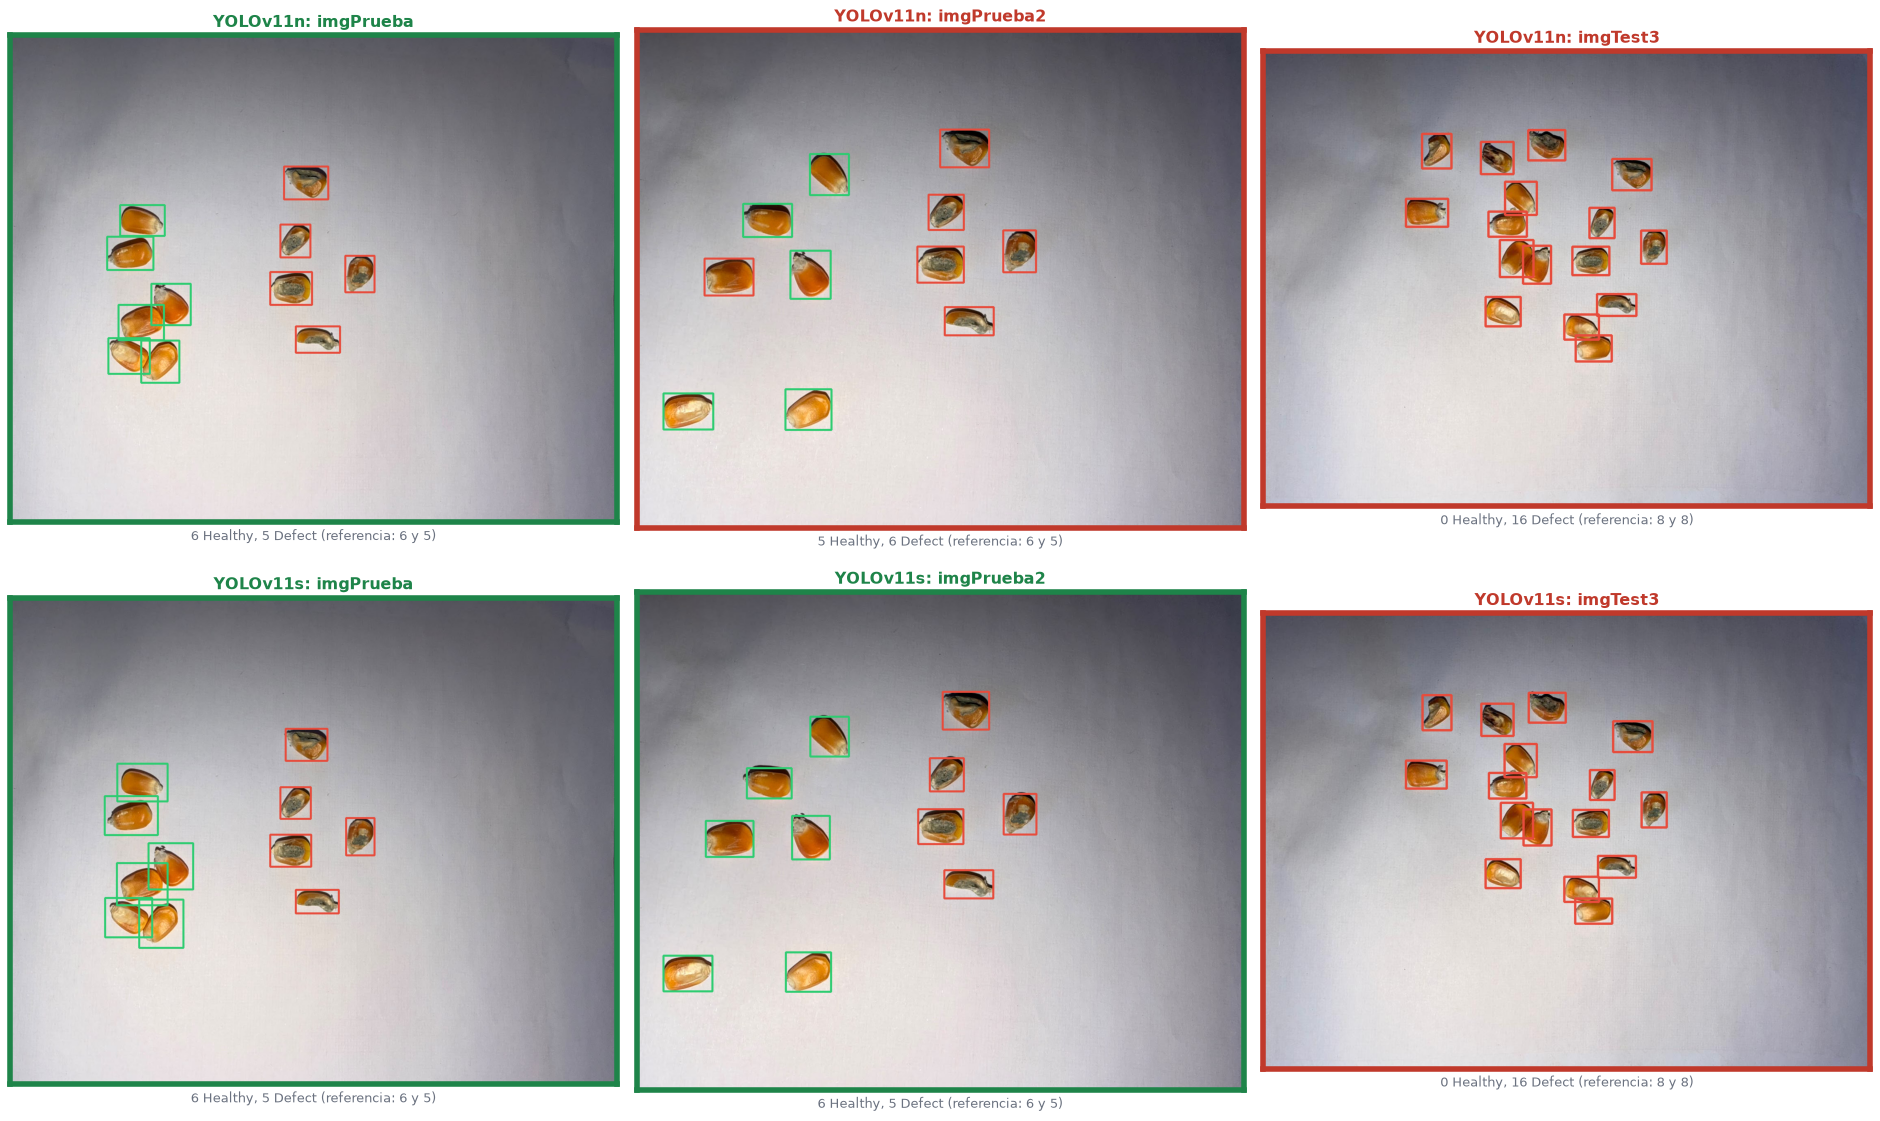

In [5]:
# Predicciones de cada modelo (semilla 42): verde Healthy, rojo Defect
fig, axes = plt.subplots(2, 3, figsize=(19, 11.5))
for fila, m in zip(axes, ETIQUETA.values()):
    for ax, s in zip(fila, FOTOS_STEMS):
        f = res[(res.foto == s) & (res.modelo == m) & (res.semilla == 42)].iloc[0]
        img = cv2.cvtColor(REF[s][0], cv2.COLOR_BGR2RGB)
        vista = E.dibujar(E.dibujar(img, f['cajas'][f['clases'] == 0], E.CAJA_OK, 4), f['cajas'][f['clases'] == 1], E.CAJA_MAL, 4)
        bien = f['sanos acertados'] == 1 and f['defectuosos acertados'] == 1
        E.mostrar(ax, vista, f'{m}: {s}', f"{f['Healthy predichos']} Healthy, {f['Defect predichos']} Defect "
                  f"(referencia: {f['sanos']} y {f['defectuosos']})", estado='ok' if bien else 'mal')
C.guardar(SALIDA, 'predicciones.png')

## 3. Causa del fallo en `imgTest3`

Se prueban, solo con inferencia, los factores que distinguen a `imgTest3` de las otras fotos.

**Pruebas sobre `imgTest3`** (¿qué la corrige?):
- **Color:** balance de blancos *gray world* y saturación reducida al 65 %.
- **Escala:** inferencia a 960, 1600 y 1920 px.
- **Contexto:** se borran de la imagen los granos defectuosos (o los sanos) por *inpainting*, sin tocar los demás.

**Pruebas sobre `imgPrueba`** (¿qué la rompe?):
- **Compresión JPEG:** calidad 50 y 30.
- **Desenfoque gaussiano:** σ = 1.5 y 2.5.

In [6]:
def gray_world(img):
    f = img.astype(np.float32)
    return np.clip(f * (f.mean((0, 1)).mean() / f.mean((0, 1))), 0, 255).astype(np.uint8)

def saturacion(img, factor):
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV).astype(np.float32)
    hsv[..., 1] *= factor
    return cv2.cvtColor(hsv.clip(0, 255).astype(np.uint8), cv2.COLOR_HSV2BGR)

def borrar(img, cajas, margen=6):
    m = np.zeros(img.shape[:2], np.uint8)
    for x1, y1, x2, y2 in cajas.astype(int):
        m[max(y1 - margen, 0):y2 + margen, max(x1 - margen, 0):x2 + margen] = 255
    return cv2.inpaint(img, m, 7, cv2.INPAINT_TELEA)

def jpeg(img, q):
    return cv2.imdecode(cv2.imencode('.jpg', img, [cv2.IMWRITE_JPEG_QUALITY, q])[1], cv2.IMREAD_COLOR)

def prueba(stem, variantes):
    img, cajas, cl = REF[stem]
    filas = []
    for nombre, (x, imgsz, sub) in variantes.items():
        keep = np.ones(len(cl), bool) if sub is None else (cl == sub)
        for m in MODELOS:
            for f in evaluar(x, cajas[keep], cl[keep], m, imgsz):
                filas.append({'prueba': nombre, 'modelo': f['modelo'], 'detecciones': f['detecciones'],
                              'sanos acertados': f['sanos acertados'], 'defectuosos acertados': f['defectuosos acertados']})
    t = pd.DataFrame(filas).groupby(['prueba', 'modelo'], sort=False).mean().unstack('modelo')
    return t.round(2)

img3, cajas3, cl3 = REF['imgTest3']
VARIANTES_T3 = {'original': (img3, E.IMGSZ, None),
                'gray world': (gray_world(img3), E.IMGSZ, None),
                'saturación × 0.65': (saturacion(img3, 0.65), E.IMGSZ, None),
                'imgsz 960': (img3, 960, None), 'imgsz 1600': (img3, 1600, None), 'imgsz 1920': (img3, 1920, None),
                'sin defectuosos': (borrar(img3, cajas3[cl3 == 1]), E.IMGSZ, 0),
                'sin sanos': (borrar(img3, cajas3[cl3 == 0]), E.IMGSZ, 1)}
print('imgTest3 (media de las 3 semillas; con un grupo borrado, solo se evalúan los granos que quedan)')
display(prueba('imgTest3', VARIANTES_T3))

img1 = REF['imgPrueba'][0]
VARIANTES_P1 = {'original': (img1, E.IMGSZ, None), 'JPEG calidad 50': (jpeg(img1, 50), E.IMGSZ, None),
                'JPEG calidad 30': (jpeg(img1, 30), E.IMGSZ, None),
                'desenfoque σ 1.5': (cv2.GaussianBlur(img1, (0, 0), 1.5), E.IMGSZ, None),
                'desenfoque σ 2.5': (cv2.GaussianBlur(img1, (0, 0), 2.5), E.IMGSZ, None)}
print('imgPrueba')
display(prueba('imgPrueba', VARIANTES_P1))

imgTest3 (media de las 3 semillas; con un grupo borrado, solo se evalúan los granos que quedan)


detecciones          sanos acertados           \
modelo               YOLOv11n YOLOv11s        YOLOv11n YOLOv11s   
prueba                                                            
original                16.00     16.0            0.25     0.00   
gray world              16.00     16.0            0.21     0.00   
saturación × 0.65       16.00     16.0            0.25     0.00   
imgsz 960               16.00     16.0            0.17     0.17   
imgsz 1600              16.00     16.0            0.33     0.12   
imgsz 1920              16.00     16.0            0.42     0.17   
sin defectuosos          8.00      8.0            1.00     1.00   
sin sanos                7.67      8.0             NaN      NaN   

                  defectuosos acertados           
modelo                         YOLOv11n YOLOv11s  
prueba                                            
original                           1.00      1.0  
gray world                         1.00      1.0  
saturación × 0.65                  1.00      1.0  
imgsz 960                          1.00      1.0  
imgsz 1600                         1.00      1.0  
imgsz 1920                         1.00      1.0  
sin defectuosos                     NaN      NaN  
sin sanos                          0.96      1.0

imgPrueba


detecciones          sanos acertados           \
modelo              YOLOv11n YOLOv11s        YOLOv11n YOLOv11s   
prueba                                                           
original               10.67    11.33            1.00      1.0   
JPEG calidad 50        10.67    11.33            0.94      1.0   
JPEG calidad 30        10.67    11.33            0.67      1.0   
desenfoque σ 1.5       11.00    11.00            1.00      1.0   
desenfoque σ 2.5       10.33    11.00            1.00      1.0   

                 defectuosos acertados           
modelo                        YOLOv11n YOLOv11s  
prueba                                           
original                          0.93      1.0  
JPEG calidad 50                   0.93      1.0  
JPEG calidad 30                   0.93      1.0  
desenfoque σ 1.5                  1.00      1.0  
desenfoque σ 2.5                  0.87      1.0

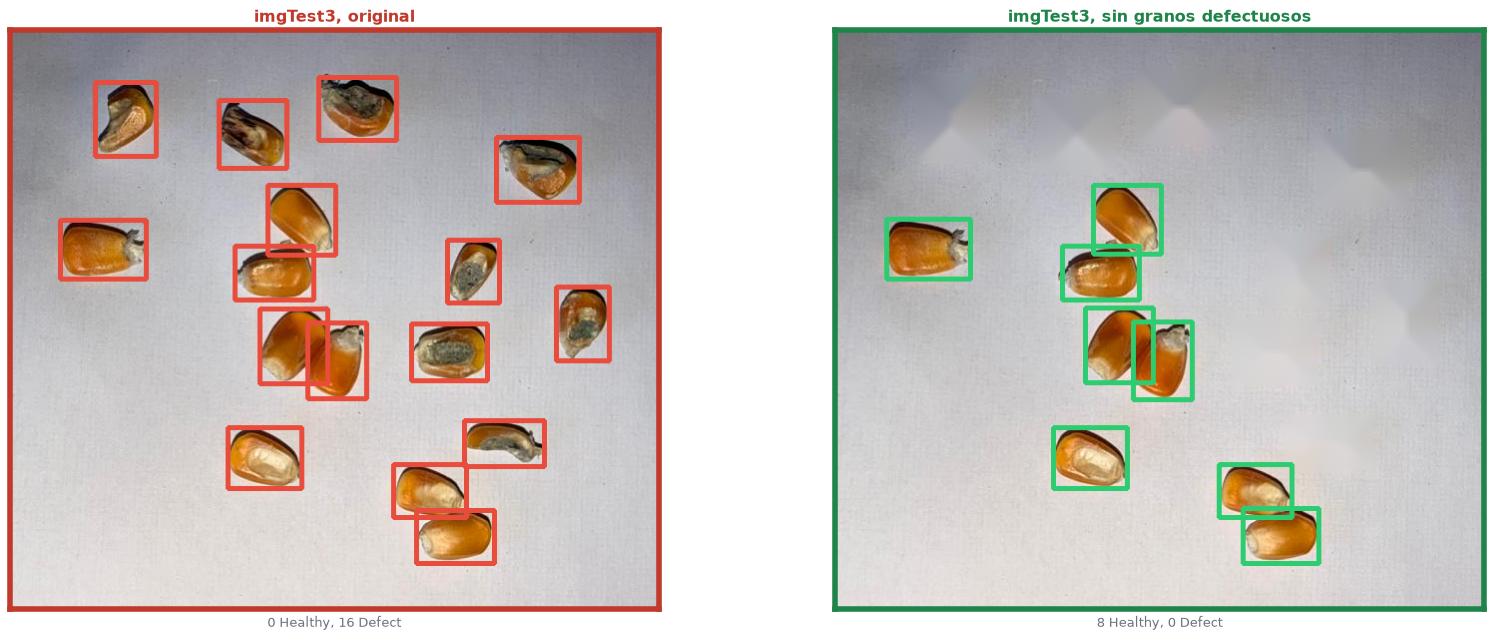

In [7]:
# imgTest3 original y sin granos defectuosos, con las predicciones de YOLOv11s (semilla 42)
fig, axes = plt.subplots(1, 2, figsize=(17, 6.6))
mod = dict(MODELOS['yolo11s'])[42]
for ax, (nombre, x) in zip(axes, (('original', img3), ('sin granos defectuosos', VARIANTES_T3['sin defectuosos'][0]))):
    r = mod.predict(x, imgsz=E.IMGSZ, conf=CFG['yolo11s']['conf_conteo'], agnostic_nms=True, verbose=False)[0]
    pb, pc = r.boxes.xyxy.cpu().numpy(), r.boxes.cls.cpu().numpy().astype(int)
    vista = E.dibujar(E.dibujar(cv2.cvtColor(x, cv2.COLOR_BGR2RGB), pb[pc == 0], E.CAJA_OK, 3), pb[pc == 1], E.CAJA_MAL, 3)
    E.mostrar(ax, vista[120:700, 250:900], f'imgTest3, {nombre}', f'{(pc == 0).sum()} Healthy, {(pc == 1).sum()} Defect',
              estado='mal' if nombre == 'original' else 'ok')
C.guardar(SALIDA, 'contexto_imgTest3.png')

**Escenas mezcladas en el entrenamiento.** Cuántas imágenes de `train` tienen granos de las dos clases, qué parte de los granos sanos está en ellas y, en esas imágenes, a qué distancia queda cada grano sano del defectuoso más cercano (en lados de grano). Se compara con las fotos propias.

In [8]:
def distancias(cajas, cl):
    """Distancia de cada grano sano al defectuoso más cercano, en lados de grano (mediana de la imagen)."""
    if not ((cl == 0).any() and (cl == 1).any()):
        return np.array([])
    c = np.stack([(cajas[:, 0] + cajas[:, 2]) / 2, (cajas[:, 1] + cajas[:, 3]) / 2], 1)
    lado = np.median(np.sqrt((cajas[:, 2] - cajas[:, 0]) * (cajas[:, 3] - cajas[:, 1])))
    d = np.linalg.norm(c[cl == 0][:, None] - c[cl == 1][None], axis=2).min(1)
    return d / lado

mezcla, dist, sanos_total = [], [], 0
for p in sorted((E.FINAL / 'train' / 'images').glob('*.jpg')):
    _, cajas, cl, _ = E.cargar(p.stem, 'train')
    mezcla.append(len(set(cl)) > 1); dist.extend(distancias(cajas, cl)); sanos_total += int((cl == 0).sum())
dist = np.array(dist)
filas = {'Data_final train': {'imágenes con las dos clases': f'{np.mean(mezcla):.0%} de {len(mezcla)}',
                              'sanos en escenas mezcladas': f'{len(dist) / sanos_total:.0%} de {sanos_total}',
                              'sanos a menos de 2 lados de un defectuoso': f'{(dist < 2).mean():.0%} de {len(dist)}',
                              'distancia mediana': f'{np.median(dist):.1f}'}}
for s, (_, cajas, cl) in REF.items():
    d = distancias(cajas, cl)
    filas[s] = {'imágenes con las dos clases': 'sí', 'sanos en escenas mezcladas': f'100% de {(cl == 0).sum()}', 'sanos a menos de 2 lados de un defectuoso': f'{(d < 2).mean():.0%} de {len(d)}',
                'distancia mediana': f'{np.median(d):.1f}'}
display(pd.DataFrame(filas).T)

,imágenes con las dos clases,sanos en escenas mezcladas,sanos a menos de 2 lados de un defectuoso,distancia mediana
Data_final train,11% de 345,8% de 5963,98% de 484,0.9
imgPrueba,sí,100% de 6,0% de 6,3.9
imgPrueba2,sí,100% de 6,0% de 6,4.5
imgTest3,sí,100% de 8,62% de 8,1.8
